In [20]:
from google.colab import files
files.upload()

Saving super_resolution_dataset.zip to super_resolution_dataset.zip


{'super_resolution_dataset.zip': b'PK\x03\x04\x14\x00\x00\x00\x08\x00;?{]\xa1\xf1l\x07\x0f$\x00\x00\n$\x00\x00\x18\x00\x00\x00dataset/low/image001.png\x01\n$\xf5\xdb\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x00@\x00\x00\x00@\x08\x02\x00\x00\x00%\x0b\xe6\x89\x00\x00#\xd1IDATx\x9c\xa5zg\x90e\xd7q^\xf7\t7\xbdw_\x9a\x9c\xd3\xce\xce\xeeb\x01,\x02\x11\x17a\x11\x98\t\x06\x81\x90\xc4`\x95T\xa5\x92Je\xd9b\xa9d\x97\xca%\x97$\x92\x96I\x89.\x89\x12U\x94DK\xa4)Q\xa6H\x82"\x01\x10\x91\x00\x16\xc0"\xedb\xb1ywfgv\xf2\xcc\x9b7\xf3r\xb8\xe9\x9c\xd3\xfe1 )\x9a6\xad\xa2\xbf\x9f}\xebV\xf5w\xba\xfb\xeb>\x01\xff\xf3\x7f\xf8\xf7\x9c\x0b\xc1\xb9\x10<\xe58~*\xcd\xa5\xe4\x8csaY\x96\xf5\xfa\xb1g\xcf\xbf\xfe\xd5\x91!q\xf5M\xbf\xba\xef\xea\xfb\x19G.\x84\xe5\xb8^:\xc5\x85\x88\x13\x95\xc4J)\xadU\xc4\x182.\x10\x10\x10\x911\xd2\xc48\xe7B\x00b\x94\xa88\x0c\xc9$\x08\x861\x8e\x08\x96m\x13@\xd0\xee\xc4*\x96B\x02\x81!\x13Ga\x10v\xb4\xd6LX\xd2r5\xa12\xc6(m\x8c\xd1Z\x93\xd1\x82\xb3s\xa7\xcf\xbf~\xfc\xe4\xd97v\xb6\x1a\x8b\xb

In [21]:
!unzip -o /content/super_resolution_dataset.zip -d /content/

Archive:  /content/super_resolution_dataset.zip
  inflating: /content/dataset/low/image001.png  
  inflating: /content/dataset/high/image001.png  
  inflating: /content/dataset/low/image002.png  
  inflating: /content/dataset/high/image002.png  
  inflating: /content/dataset/low/image003.png  
  inflating: /content/dataset/high/image003.png  
  inflating: /content/dataset/low/image004.png  
  inflating: /content/dataset/high/image004.png  
  inflating: /content/dataset/low/image005.png  
  inflating: /content/dataset/high/image005.png  
  inflating: /content/dataset/low/image006.png  
  inflating: /content/dataset/high/image006.png  
  inflating: /content/dataset/low/image007.png  
  inflating: /content/dataset/high/image007.png  
  inflating: /content/dataset/low/image008.png  
  inflating: /content/dataset/high/image008.png  
  inflating: /content/dataset/low/image009.png  
  inflating: /content/dataset/high/image009.png  
  inflating: /content/dataset/low/image010.png  
  inflating:

In [22]:
!pip install tensorflow numpy pillow matplotlib

Epoch 1/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step - loss: 0.1005
Epoch 2/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - loss: 0.0951
Epoch 3/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - loss: 0.0917
Epoch 4/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - loss: 0.0894
Epoch 5/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - loss: 0.0880


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 976ms/step


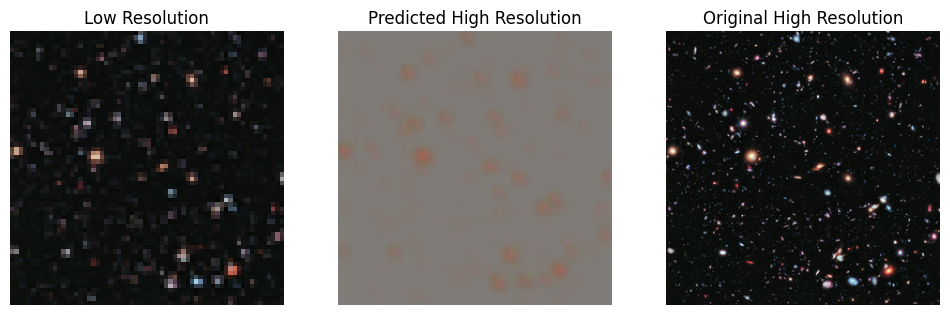

In [23]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import *
from tensorflow.keras.preprocessing.image import load_img
import numpy as np, os
import matplotlib.pyplot as plt

# Dataset
X=[]; Y=[]

for f in os.listdir("/content/dataset/low/"):

    # Low image
    X.append(np.array(load_img("/content/dataset/low/"+f,
                    target_size=(64,64)))/255.0)

    # High image
    Y.append(np.array(load_img("/content/dataset/high/"+f,
                    target_size=(256,256)))/255.0)

# Convert to array
X=np.array(X)
Y=np.array(Y)

# Input
i=Input((64,64,3))

# Conv
x=Conv2D(64,(3,3),activation='relu',padding='same')(i)

# Upsample
x=UpSampling2D((2,2))(x)

# Conv
x=Conv2D(64,(3,3),activation='relu',padding='same')(x)

# Upsample
x=UpSampling2D((2,2))(x)

# Output
o=Conv2D(3,(3,3),activation='sigmoid',padding='same')(x)

# Model
model=Model(i,o)

# Compile
model.compile(optimizer='adam',loss='mse')

# Train
model.fit(X,Y,epochs=5)

# Save
model.save("/content/esrgan.h5")

# Predict
pred=model.predict(X[0:1])

# Display output
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(X[0])
plt.title("Low Resolution")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(pred[0])
plt.title("Predicted High Resolution")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(Y[0])
plt.title("Original High Resolution")
plt.axis("off")

plt.show()